In [3]:
# EDA – Khảo sát bộ dữ liệu Dog Localization & Classification

## 1. Kiểm tra sự khớp nhau giữa thư mục `anno` và `img`

In [18]:
import os
from pathlib import Path

DATA_DIR = Path("data")
ANNO_DIR = DATA_DIR / "anno_resized" # "anno"
IMG_DIR  = DATA_DIR / "img_resized" # "img"

# ── 1a. So sánh tên thư mục con ──────────────────────────────────────────────
anno_folders = set(p.name for p in ANNO_DIR.iterdir() if p.is_dir())
img_folders  = set(p.name for p in IMG_DIR.iterdir()  if p.is_dir())

only_in_anno = anno_folders - img_folders
only_in_img  = img_folders  - anno_folders
common       = anno_folders & img_folders

print("=" * 60)
print(f"  Tổng thư mục trong anno : {len(anno_folders)}")
print(f"  Tổng thư mục trong img  : {len(img_folders)}")
print(f"  Thư mục KHỚP nhau       : {len(common)}")
print(f"  Chỉ có trong anno       : {len(only_in_anno)} → {sorted(only_in_anno)}")
print(f"  Chỉ có trong img        : {len(only_in_img)}  → {sorted(only_in_img)}")
print("=" * 60)


  Tổng thư mục trong anno : 20
  Tổng thư mục trong img  : 20
  Thư mục KHỚP nhau       : 20
  Chỉ có trong anno       : 0 → []
  Chỉ có trong img        : 0  → []


## 2. Kiểm tra sự khớp giữa file ảnh và file annotation (XML không đuôi)

In [19]:
import xml.etree.ElementTree as ET
from collections import defaultdict

IMG_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".gif", ".tiff", ".webp"}

mismatch_summary = {}   # { class_folder: { 'img_only': [...], 'anno_only': [...] } }
total_matched    = 0
total_img_only   = 0
total_anno_only  = 0
invalid_xml      = []   # annotation files that can't be parsed as XML

for cls_folder in sorted(common):
    anno_cls = ANNO_DIR / cls_folder
    img_cls  = IMG_DIR  / cls_folder

    # Lấy tên stem ảnh (bỏ đuôi .jpg …)
    img_stems = {
        p.stem
        for p in img_cls.iterdir()
        if p.is_file() and p.suffix.lower() in IMG_EXTS
    }

    # Lấy tên file anno (không có đuôi → stem == name)
    anno_names = set()
    for p in anno_cls.iterdir():
        if p.is_file():
            # Xác nhận nội dung là XML hợp lệ
            try:
                ET.parse(p)
                anno_names.add(p.name)
            except ET.ParseError:
                invalid_xml.append(str(p))

    only_img  = img_stems - anno_names
    only_anno = anno_names - img_stems
    matched   = img_stems & anno_names

    total_matched   += len(matched)
    total_img_only  += len(only_img)
    total_anno_only += len(only_anno)

    if only_img or only_anno:
        mismatch_summary[cls_folder] = {
            "img_only":  sorted(only_img),
            "anno_only": sorted(only_anno),
        }

# ── Kết quả tổng quan ────────────────────────────────────────────────────────
print("=" * 60)
print(f"  Tổng cặp (ảnh ↔ anno) KHỚP     : {total_matched}")
print(f"  Ảnh KHÔNG có anno tương ứng      : {total_img_only}")
print(f"  Anno KHÔNG có ảnh tương ứng      : {total_anno_only}")
print(f"  File anno KHÔNG phải XML hợp lệ  : {len(invalid_xml)}")
print("=" * 60)

if invalid_xml:
    print("\n  Các file anno không parse được XML:")
    for f in invalid_xml:
        print("   ", f)

if mismatch_summary:
    print("\n  Các class bị lệch (img ≠ anno):")
    for cls, diff in mismatch_summary.items():
        print(f"\n  [{cls}]")
        if diff["img_only"]:
            print(f"    Ảnh thiếu anno ({len(diff['img_only'])}): {diff['img_only'][:5]}{'...' if len(diff['img_only'])>5 else ''}")
        if diff["anno_only"]:
            print(f"    Anno thiếu ảnh ({len(diff['anno_only'])}): {diff['anno_only'][:5]}{'...' if len(diff['anno_only'])>5 else ''}")
else:
    print("\n  Tất cả file ảnh và anno đều KHỚP nhau hoàn toàn!")


  Tổng cặp (ảnh ↔ anno) KHỚP     : 3537
  Ảnh KHÔNG có anno tương ứng      : 0
  Anno KHÔNG có ảnh tương ứng      : 0
  File anno KHÔNG phải XML hợp lệ  : 0

  Tất cả file ảnh và anno đều KHỚP nhau hoàn toàn!


## 3. Thống kê kích thước ảnh (Width & Height min/max)

In [20]:
from PIL import Image

widths  = []
heights = []
size_records = []   # (w, h, path)

for cls_folder in sorted(common):
    img_cls = IMG_DIR / cls_folder
    for p in img_cls.iterdir():
        if p.is_file() and p.suffix.lower() in IMG_EXTS:
            with Image.open(p) as im:
                w, h = im.size
            widths.append(w)
            heights.append(h)
            size_records.append((w, h, p))

# ── Tìm ảnh min/max ──────────────────────────────────────────────────────────
idx_wmin = widths.index(min(widths))
idx_wmax = widths.index(max(widths))
idx_hmin = heights.index(min(heights))
idx_hmax = heights.index(max(heights))

print("=" * 60)
print(f"  Tổng số ảnh đã quét   : {len(widths)}")
print()
print(f"  Width  min : {min(widths):>5}px  → {size_records[idx_wmin][2]}")
print(f"  Width  max : {max(widths):>5}px  → {size_records[idx_wmax][2]}")
print()
print(f"  Height min : {min(heights):>5}px  → {size_records[idx_hmin][2]}")
print(f"  Height max : {max(heights):>5}px  → {size_records[idx_hmax][2]}")
print("=" * 60)


  Tổng số ảnh đã quét   : 3537

  Width  min :   512px  → data\img_resized\n02085620-Chihuahua\n02085620_10074.jpg
  Width  max :   512px  → data\img_resized\n02085620-Chihuahua\n02085620_10074.jpg

  Height min :   512px  → data\img_resized\n02085620-Chihuahua\n02085620_10074.jpg
  Height max :   512px  → data\img_resized\n02085620-Chihuahua\n02085620_10074.jpg


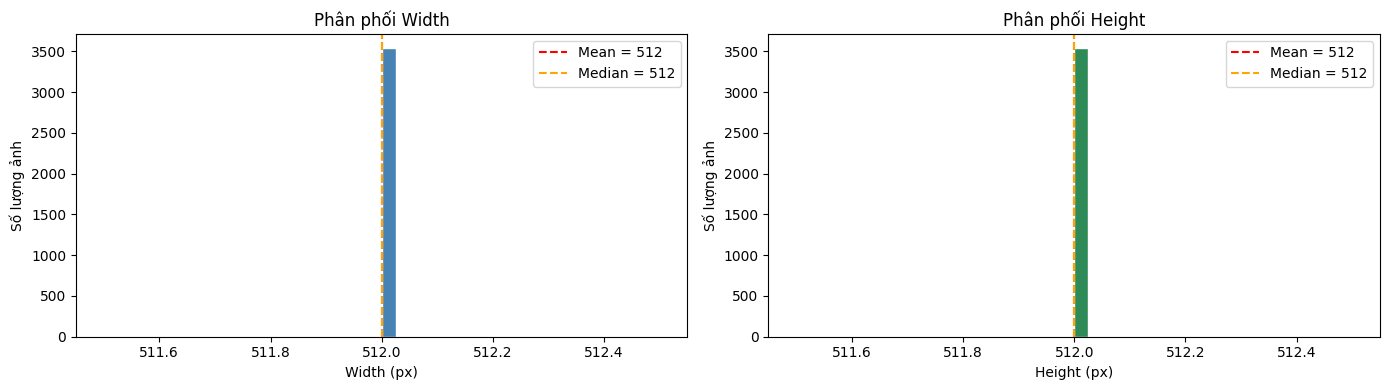

In [21]:
import matplotlib.pyplot as plt
import numpy as np

fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(widths,  bins=40, color="steelblue", edgecolor="white")
axes[0].set_title("Phân phối Width")
axes[0].set_xlabel("Width (px)")
axes[0].set_ylabel("Số lượng ảnh")
axes[0].axvline(np.mean(widths),  color="red",    linestyle="--", label=f"Mean = {np.mean(widths):.0f}")
axes[0].axvline(np.median(widths),color="orange", linestyle="--", label=f"Median = {np.median(widths):.0f}")
axes[0].legend()

axes[1].hist(heights, bins=40, color="seagreen",  edgecolor="white")
axes[1].set_title("Phân phối Height")
axes[1].set_xlabel("Height (px)")
axes[1].set_ylabel("Số lượng ảnh")
axes[1].axvline(np.mean(heights),  color="red",    linestyle="--", label=f"Mean = {np.mean(heights):.0f}")
axes[1].axvline(np.median(heights),color="orange", linestyle="--", label=f"Median = {np.median(heights):.0f}")
axes[1].legend()

plt.tight_layout()
plt.show()


## 4. Resize anh + scale bounding box (ThreadPoolExecutor)

In [16]:
import xml.etree.ElementTree as ET
from concurrent.futures import ThreadPoolExecutor
from PIL import Image

# ── Cau hinh ─────────────────────────────────────────────────────────────────
TARGET_T = 512                          # khung vuong T x T
PAD_COLOR = (114, 114, 114)             # mau padding (gray - chuan YOLO)

OUT_IMG_DIR  = DATA_DIR / "img_resized"
OUT_ANNO_DIR = DATA_DIR / "anno_resized"

# ── Worker: letterbox 1 anh ───────────────────────────────────────────────────
# B1: S = min(T/W, T/H)
# B2: new_w = round(W*S), new_h = round(H*S)
# B3: pad_w = T - new_w,  pad_h = T - new_h
# B4: pad_left = pad_w//2, pad_top = pad_h//2  (center pad)
def letterbox_image(args):
    src, dst = args
    dst.parent.mkdir(parents=True, exist_ok=True)
    with Image.open(src) as im:
        W, H = im.size
        S     = min(TARGET_T / W, TARGET_T / H)
        new_w = round(W * S)
        new_h = round(H * S)
        pad_w = TARGET_T - new_w
        pad_h = TARGET_T - new_h
        pad_left = pad_w // 2
        pad_top  = pad_h // 2

        scaled = im.resize((new_w, new_h), Image.LANCZOS)
        canvas = Image.new("RGB", (TARGET_T, TARGET_T), PAD_COLOR)
        canvas.paste(scaled, (pad_left, pad_top))
        canvas.save(dst, quality=95)

# ── Worker: letterbox bbox trong 1 file anno ──────────────────────────────────
def letterbox_anno(args):
    src, dst = args
    dst.parent.mkdir(parents=True, exist_ok=True)
    tree = ET.parse(src)
    root = tree.getroot()

    W = int(root.find("size/width").text)
    H = int(root.find("size/height").text)
    S     = min(TARGET_T / W, TARGET_T / H)
    new_w = round(W * S)
    new_h = round(H * S)
    pad_left = (TARGET_T - new_w) // 2
    pad_top  = (TARGET_T - new_h) // 2

    # Cap nhat size
    root.find("size/width").text  = str(TARGET_T)
    root.find("size/height").text = str(TARGET_T)

    # Anh xa toa do bbox: scale roi cong offset padding
    for bb in root.iter("bndbox"):
        bb.find("xmin").text = str(round(int(bb.find("xmin").text) * S) + pad_left)
        bb.find("ymin").text = str(round(int(bb.find("ymin").text) * S) + pad_top)
        bb.find("xmax").text = str(round(int(bb.find("xmax").text) * S) + pad_left)
        bb.find("ymax").text = str(round(int(bb.find("ymax").text) * S) + pad_top)

    tree.write(dst)

# ── Build task list ───────────────────────────────────────────────────────────
img_tasks = [
    (src, OUT_IMG_DIR / src.parent.name / src.name)
    for cls in sorted(common)
    for src in (IMG_DIR / cls).iterdir()
    if src.is_file() and src.suffix.lower() in IMG_EXTS
]

anno_tasks = [
    (src, OUT_ANNO_DIR / src.parent.name / src.name)
    for cls in sorted(common)
    for src in (ANNO_DIR / cls).iterdir()
    if src.is_file()
]

print(f"Tasks: {len(img_tasks)} images | {len(anno_tasks)} annotations -> {TARGET_T}x{TARGET_T} (letterbox)")
print(f"Output img  : {OUT_IMG_DIR}")
print(f"Output anno : {OUT_ANNO_DIR}")


Tasks: 3537 images | 3537 annotations -> 512x512 (letterbox)
Output img  : data\img_resized
Output anno : data\anno_resized


Done. 3537 images + 3537 annotations in 23.7s

Sample check [n02085620_10074]
  size : 512 x 512
  bbox : xmin=111  ymin=10  xmax=368  ymax=510


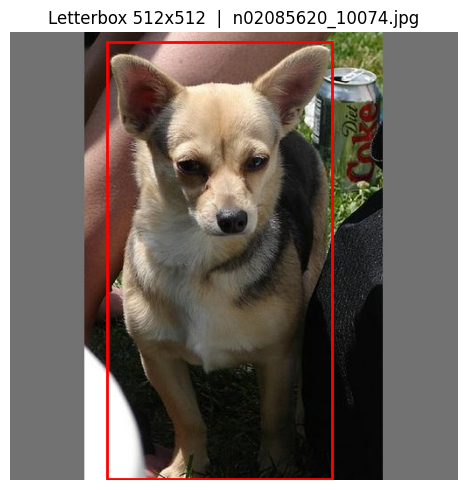

In [17]:
import time

t0 = time.time()

with ThreadPoolExecutor() as pool:
    list(pool.map(letterbox_image, img_tasks))
    list(pool.map(letterbox_anno,  anno_tasks))

elapsed = time.time() - t0
print(f"Done. {len(img_tasks)} images + {len(anno_tasks)} annotations in {elapsed:.1f}s")

# Kiem tra nhanh: doc lai 1 anno + hien thi ảnh co bbox
sample_src, sample_dst = anno_tasks[0]
root_check = ET.parse(sample_dst).getroot()
print(f"\nSample check [{sample_dst.name}]")
print(f"  size : {root_check.find('size/width').text} x {root_check.find('size/height').text}")
for bb in root_check.iter("bndbox"):
    print(f"  bbox : xmin={bb.find('xmin').text}  ymin={bb.find('ymin').text}"
          f"  xmax={bb.find('xmax').text}  ymax={bb.find('ymax').text}")

# Visual check
import matplotlib.pyplot as plt
import matplotlib.patches as patches

img_sample_dst = img_tasks[0][1]
with Image.open(img_sample_dst) as im:
    fig, ax = plt.subplots(figsize=(5, 5))
    ax.imshow(im)
    for bb in root_check.iter("bndbox"):
        x1 = int(bb.find("xmin").text)
        y1 = int(bb.find("ymin").text)
        x2 = int(bb.find("xmax").text)
        y2 = int(bb.find("ymax").text)
        rect = patches.Rectangle((x1, y1), x2-x1, y2-y1,
                                  linewidth=2, edgecolor="red", facecolor="none")
        ax.add_patch(rect)
    ax.set_title(f"Letterbox {TARGET_T}x{TARGET_T}  |  {img_sample_dst.name}")
    ax.axis("off")
    plt.tight_layout()
    plt.show()
